# 1. Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 2. Load the training and frozen test data

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test_300.csv")

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

print("\nTraining labels:")
print(train_df["sentiment"].value_counts())

print("\nTest labels:")
print(test_df["sentiment"].value_counts())

Training set: (39665, 3)
Test set: (300, 3)

Training labels:
sentiment
positive    19907
negative    19758
Name: count, dtype: int64

Test labels:
sentiment
positive    151
negative    149
Name: count, dtype: int64


# 3. Separate X and y

In [3]:
X_train = train_df["review"]
y_train = train_df["sentiment"]

X_test = test_df["review"]
y_test = test_df["sentiment"]

# 4. Create the TF-IDF vectorizer

In [5]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (39665, 20000)
Test TF-IDF shape: (300, 20000)


# 5. Create the Naïve Bayes model

In [6]:
nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


# 6. Run predictions

In [7]:
start_time = time.perf_counter()

nb_predictions = nb_model.predict(X_test_tfidf)

end_time = time.perf_counter()

total_time = end_time - start_time

print(f"Prediction time: {total_time:.6f} seconds")

Prediction time: 0.004389 seconds


In [8]:
test_df["nb_prediction"] = nb_predictions

In [9]:
test_df[
    ["review", "sentiment", "nb_prediction"]
].head(10)

,review,sentiment,nb_prediction
0,"This isn't the worst movie I've ever seen, but...",negative,negative
1,I see this movie as a poor tribute to the old ...,negative,negative
2,This is the kind of movie which shows the pauc...,negative,negative
3,I was pretty young when this came out in the U...,positive,positive
4,I went to see this because of snipes / statham...,negative,negative
5,"The fourth ""Tremors"" feature goes back in time...",negative,negative
6,I watched this movie so that you don't have to...,negative,negative
7,Burt Reynold's Direct's and star's in this gre...,positive,positive
8,How can anyone even begin to like this film is...,negative,negative
9,"This was my first, and probably the last Angel...",negative,negative


# 7. Accuracy

In [10]:
nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

print(f"Naive Bayes Accuracy: {nb_accuracy:.4f}")
print(f"Naive Bayes Accuracy: {nb_accuracy * 100:.2f}%")

Naive Bayes Accuracy: 0.8400
Naive Bayes Accuracy: 84.00%


# 8. Macro-F1

In [12]:
nb_macro_f1 = f1_score(
    y_test,
    nb_predictions,
    average="macro"
)

print(f"Naive Bayes Macro-F1: {nb_macro_f1:.4f}")

Naive Bayes Macro-F1: 0.8400


# 9. Seconds per 1,000 predictions

In [13]:
seconds_per_1000 = (
    total_time / len(test_df)
) * 1000

print(
    f"Seconds per 1,000 predictions: "
    f"{seconds_per_1000:.6f}"
)

Seconds per 1,000 predictions: 0.014630


# 10. Confusion matrix

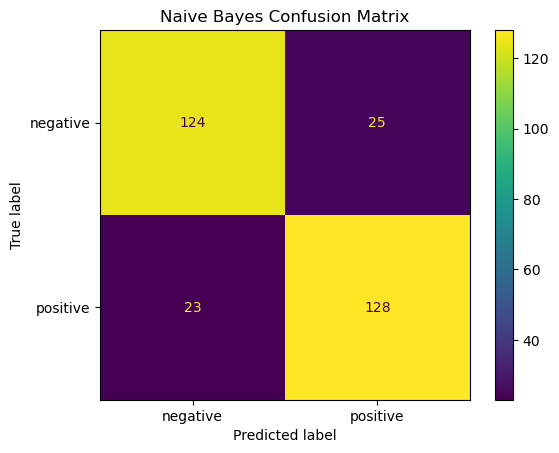

In [14]:
cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=["negative", "positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["negative", "positive"]
)

display.plot()

plt.title("Naive Bayes Confusion Matrix")
plt.show()

# 11. Inspect incorrect predictions

In [15]:
nb_errors = test_df[
    test_df["sentiment"] != test_df["nb_prediction"]
].copy()

print(
    "Number of incorrect predictions:",
    len(nb_errors)
)

nb_errors[
    ["review", "sentiment", "nb_prediction"]
].head(10)

Number of incorrect predictions: 48


,review,sentiment,nb_prediction
16,I have read and enjoyed many of James Lee Burk...,negative,positive
20,A lot of things in this futuristic satire are ...,positive,negative
29,John Boorman's 1998 The General was hailed as ...,negative,positive
32,This PM Entertainment production is laced with...,positive,negative
33,"I liked this movie, Although halfway through i...",positive,negative
34,Im not a big Tim Matheson fan but i have to ad...,positive,negative
36,Simply miserable Lana Turner-Ezio Pinza vehicl...,negative,positive
42,Ghoulies IV may not be the best out of the ser...,positive,negative
49,"All in all, don't expect much and you won't be...",negative,positive
63,I've watched the first 15 minutes and I can te...,negative,positive


# 12. Save predictions

In [16]:
test_df.to_csv(
    "naive_bayes_predictions.csv",
    index=False
)

print("Naive Bayes predictions saved.")

Naive Bayes predictions saved.


# 13. Save the trained model

In [17]:
joblib.dump(
    nb_model,
    "naive_bayes_model.pkl"
)

joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved.")

Model and TF-IDF vectorizer saved.


# 14. Saving Metrics

In [18]:
nb_results = pd.DataFrame({
    "model": ["NLTK + Naive Bayes"],
    "accuracy": [nb_accuracy],
    "macro_f1": [nb_macro_f1],
    "seconds_per_1000": [seconds_per_1000],
    "cost_per_1000": [0.0]
})

nb_results

,model,accuracy,macro_f1,seconds_per_1000,cost_per_1000
0,NLTK + Naive Bayes,0.84,0.839972,0.01463,0.0


In [19]:
nb_results.to_csv(
    "naive_bayes_metrics.csv",
    index=False
)

print("Naive Bayes metrics saved.")

Naive Bayes metrics saved.


# Summary

In [20]:
print("NAIVE BAYES RESULTS")
print("=" * 45)

print(f"Training examples: {len(train_df):,}")
print(f"Test examples: {len(test_df):,}")
print(f"Accuracy: {nb_accuracy:.4f}")
print(f"Macro-F1: {nb_macro_f1:.4f}")
print(f"Total prediction time: {total_time:.6f} seconds")
print(f"Seconds / 1,000 predictions: {seconds_per_1000:.6f}")
print("Cost / 1,000 predictions: ~$0")
print(f"Incorrect predictions: {len(nb_errors)}")

NAIVE BAYES RESULTS
Training examples: 39,665
Test examples: 300
Accuracy: 0.8400
Macro-F1: 0.8400
Total prediction time: 0.004389 seconds
Seconds / 1,000 predictions: 0.014630
Cost / 1,000 predictions: ~$0
Incorrect predictions: 48
